# Support Vector Machine (RBF) - Acoustic Event Classification
### Sonobuoy Sound Detective: Offline Underwater Acoustic Event Detection
**Assigned Team Member:** Person 2 (Kernel & Probabilistic Classifiers)  
**Algorithm:** Soft-margin SVM with an RBF kernel  
**Algorithm Identifier:** `svm_rbf`  
**Folder:** `02_person2_svm_and_naive_bayes/`

---

## 1. Algorithm Overview & Theoretical Foundation
**Support Vector Machine (SVM) with Radial Basis Function (RBF) Kernel** separates classes by projecting feature vectors into a high-dimensional Hilbert space:
$$K(\mathbf{x}, \mathbf{z}) = \exp\left(-\gamma \|\mathbf{x} - \mathbf{z}\|^2\right)$$
Slack variables $\xi_i$ and penalty $C$ govern soft-margin boundaries for non-linearly separable acoustic clusters.

**How the settings work**
- **Margin and slack:** the SVM finds the boundary with the widest margin between classes. Slack variables $\xi_i$ allow some points inside the margin or on the wrong side:
$$\min_{\mathbf{w}, b, \xi} \; \frac{1}{2}\|\mathbf{w}\|^2 + C \sum_i \xi_i$$
- **`C`:** sets the cost of those violations. A small `C` gives a smoother boundary that can underfit, and a large `C` follows the training data more closely.
- **`gamma`:** sets how far one training point's influence reaches. A small `gamma` gives a smooth boundary, and a large `gamma` gives a very local one that can overfit.
- **Multiple classes:** `SVC` trains one classifier for each pair of classes.
- **Probabilities:** an SVM doesn't produce probabilities directly. With `probability=True`, `SVC` fits Platt scaling, a logistic model on its decision scores. So `predict()` and the top probability can occasionally disagree.

**Why scaling matters here:** the kernel uses distances, and our feature scales differ by about 138 million times (see `eda_person2.ipynb`). Without scaling, the largest features would dominate.

This notebook:
1. Loads the shared feature table (`../data/features/features.csv`) and the 66 selected features.
2. Uses the official Train / Validation / Test split (77% / 9.5% / 13.5%), with no clip shared between splits.
3. Fits `StandardScaler` on training data only, inside a `Pipeline` during tuning.
4. Tunes hyperparameters with 5-fold `StratifiedGroupKFold`, grouped by `source_clip_id`.
5. Checks the chosen model and its probabilities on the validation set.
6. Evaluates once on the held-out test set (Accuracy, Macro Precision, Macro Recall, Macro F1, Multi-Class ROC-AUC).
7. Saves the **Confusion Matrix**, **ROC Curves** and **Interpretability Plots** to `plots/`.
8. Exports the final model, scaler and metrics to `models/` for the final comparison.

**Data:** 3,579 segments in 3 classes (`vessel_like`, `ambient`, `unknown`). `marine_life` has no data.
**Main metric:** Macro F1, because 92% of segments are `vessel_like`, so accuracy alone is misleading.


In [61]:
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import (
    GridSearchCV, StratifiedGroupKFold, StratifiedKFold,
    cross_val_predict, cross_val_score, cross_validate, learning_curve
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, log_loss,
    roc_auc_score, confusion_matrix, classification_report, roc_curve, auc,
    average_precision_score, precision_recall_curve
)

Path("plots").mkdir(parents=True, exist_ok=True)
Path("models").mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

ALGO_NAME = "Support Vector Machine (RBF)"
FILE_SLUG = "svm_rbf"
print(f"Configured notebook for {ALGO_NAME} ({FILE_SLUG}).")

Configured notebook for Support Vector Machine (RBF) (svm_rbf).


## 2. Load Shared Acoustic Features and Selected Descriptors


In [62]:
csv_path = Path("../data/features/features.csv")
sel_path = Path("../data/features/selected_features.json")

df = pd.read_csv(csv_path)
with open(sel_path) as f:
    feature_cols = json.load(f)["selected_features"]

missing = [c for c in feature_cols if c not in df.columns]
assert not missing, f"Selected features missing from the data: {missing}"

print(f"Loaded {len(feature_cols)} selected features.")
print(f"Total samples: {len(df)}")
print(f"Class distribution:\n{df['label'].value_counts()}")

Loaded 66 selected features.
Total samples: 3579
Class distribution:
label
vessel_like    3304
ambient         192
unknown          83
Name: count, dtype: int64


## 3. Official Train / Validation / Test Split & Feature Scaling

In [63]:
le = LabelEncoder()
df["target"] = le.fit_transform(df["label"])
classes = list(le.classes_)
num_classes = len(classes)

assert set(df["split"].unique()) == {"train", "val", "test"}
train_mask = df["split"] == "train"
val_mask   = df["split"] == "val"
test_mask  = df["split"] == "test"

X_train_raw = np.nan_to_num(df.loc[train_mask, feature_cols].values, nan=0.0)
y_train     = df.loc[train_mask, "target"].values
groups_train = df.loc[train_mask, "source_clip_id"].values

X_val_raw = np.nan_to_num(df.loc[val_mask, feature_cols].values, nan=0.0)
y_val     = df.loc[val_mask, "target"].values

# LOCKED: don't use the test set until Phase 6
X_test_raw = np.nan_to_num(df.loc[test_mask, feature_cols].values, nan=0.0)
y_test     = df.loc[test_mask, "target"].values

# Used for the final fit and export. Tuning uses a Pipeline on the raw data instead.
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val   = scaler.transform(X_val_raw)
X_test  = scaler.transform(X_test_raw)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Classes: {dict(enumerate(classes))}")

Train: 2756 | Val: 341 | Test: 482
Classes: {0: 'ambient', 1: 'unknown', 2: 'vessel_like'}


### 3.1 Evaluation setup
- **Grouped CV:** one clip can produce up to 101 segments, so folds are grouped by `source_clip_id`. This keeps segments from the same clip out of both sides of a fold.
- **Evaluation helper:** gives every model the same metrics.
- **Dummy baseline:** always predicts the most common class. Any real model must beat it.

In [64]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

for fold, (tr, va) in enumerate(cv.split(X_train_raw, y_train, groups_train), start=1):
    assert not set(groups_train[tr]) & set(groups_train[va]), "Clip leaked across folds!"
    print(f"Fold {fold}: train={len(tr)} val={len(va)} "
          f"val per class={np.bincount(y_train[va], minlength=num_classes)}")
print("No clip appears on both sides of any fold.")

Fold 1: train=2340 val=416 val per class=[ 30  11 375]
Fold 2: train=2304 val=452 val per class=[ 29  12 411]
Fold 3: train=2402 val=354 val per class=[ 26  16 312]
Fold 4: train=1945 val=811 val per class=[ 31  16 764]
Fold 5: train=2033 val=723 val per class=[ 37  11 675]
No clip appears on both sides of any fold.


In [65]:
def evaluate(model, X, y):
    """Score a fitted model on already-prepared features."""
    pred = model.predict(X)
    prob = model.predict_proba(X)
    labels = list(range(num_classes))
    onehot = np.eye(num_classes)[y]

    results = {
        "accuracy": accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y, prob, multi_class="ovr", average="macro", labels=labels),
        "log_loss": log_loss(y, prob, labels=labels),
        "brier": np.mean(np.sum((prob - onehot) ** 2, axis=1)),
    }
    per_class = recall_score(y, pred, average=None, labels=labels, zero_division=0)
    for cls, value in zip(classes, per_class):
        results[f"recall_{cls}"] = value
    return results

In [66]:
dummy = DummyClassifier(strategy="most_frequent")

dummy_cv = cross_val_score(dummy, X_train, y_train, groups=groups_train,
                           cv=cv, scoring="f1_macro")
print(f"Dummy grouped CV macro F1: {dummy_cv.mean():.3f}")

dummy.fit(X_train, y_train)
print("Dummy on validation:")
print(pd.Series(evaluate(dummy, X_val, y_val)).round(3))

Dummy grouped CV macro F1: 0.318
Dummy on validation:
accuracy              0.921
macro_f1              0.320
roc_auc               0.500
log_loss              2.854
brier                 0.158
recall_ambient        0.000
recall_unknown        0.000
recall_vessel_like    1.000
dtype: float64


## 4. Hyperparameter Tuning for Support Vector Machine (RBF)
All tuning uses the **training split only**, with 5-fold CV grouped by clip. The scaler sits inside a `Pipeline`, so each fold is scaled using only its own training data.

The search runs in stages:
1. **Baselines:** does the RBF kernel beat a linear kernel and the Dummy?
2. **Coarse search:** a wide log-scale grid of `C` and `gamma`.
3. **Fine search:** a closer look around the best coarse result.
4. **Simple choice:** among results within one standard error of the best, take the smallest `C`, then the smallest `gamma`. Smaller values give a smoother model that is less likely to overfit.
5. **Class weights:** compare `balanced` with no weighting.
6. **Diagnostics and validation:** check for overfitting, then fit the final model.

In [67]:
def make_svm(**params):
    """Scaler + SVM, so scaling is refitted inside every CV fold."""
    settings = {"kernel": "rbf", "class_weight": "balanced", "random_state": RANDOM_SEED, **params}
    return Pipeline([("scaler", StandardScaler()), ("svc", SVC(**settings))])


def grouped_cv(model, label):
    """Macro F1 from grouped CV, with the train score to reveal overfitting."""
    res = cross_validate(model, X_train_raw, y_train, groups=groups_train, cv=cv,
                         scoring="f1_macro", return_train_score=True, n_jobs=-1)
    return {"model": label,
            "cv_macro_f1": res["test_score"].mean(),
            "cv_se": res["test_score"].std() / np.sqrt(cv.get_n_splits()),
            "train_macro_f1": res["train_score"].mean(),
            "gap": res["train_score"].mean() - res["test_score"].mean()}


baselines = pd.DataFrame([
    grouped_cv(DummyClassifier(strategy="most_frequent"), "Dummy (most frequent)"),
    grouped_cv(make_svm(kernel="linear"), "Linear SVM, default C"),
    grouped_cv(make_svm(), "RBF SVM, default C and gamma"),
])
print(baselines.round(3).to_string(index=False))

                       model  cv_macro_f1  cv_se  train_macro_f1   gap
       Dummy (most frequent)        0.318  0.002           0.319 0.001
       Linear SVM, default C        0.888  0.012           0.976 0.087
RBF SVM, default C and gamma        0.915  0.005           0.951 0.036


Coarse search: 36 settings in 24s
Best: {'svc__C': 100.0, 'svc__gamma': 'scale'} | CV macro F1 = 0.955


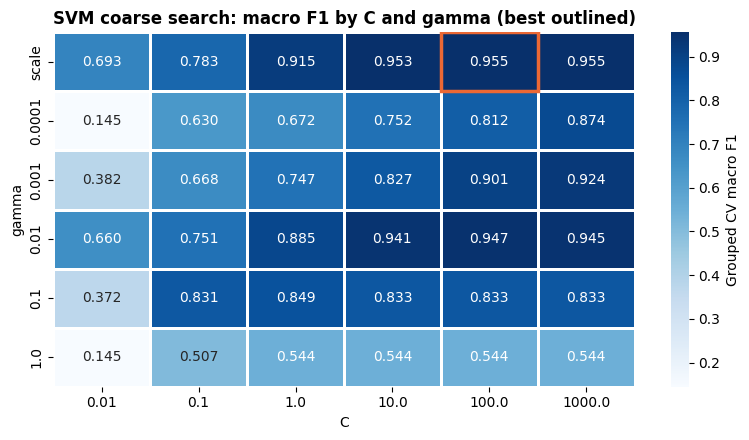

In [68]:
C_GRID = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
GAMMA_GRID = ["scale", 0.0001, 0.001, 0.01, 0.1, 1.0]
# On standardized data, gamma="scale" is about 1 / number of features
SCALE_GAMMA = 1 / len(feature_cols)


def run_search(c_values, gamma_values):
    search = GridSearchCV(make_svm(), {"svc__C": list(c_values), "svc__gamma": list(gamma_values)},
                          scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True)
    search.fit(X_train_raw, y_train, groups=groups_train)
    return search


def results_table(search):
    r = pd.DataFrame(search.cv_results_)
    return pd.DataFrame({
        "C": r["param_svc__C"].astype(float),
        "gamma_label": r["param_svc__gamma"].astype(str),
        "gamma": r["param_svc__gamma"].map(lambda g: SCALE_GAMMA if g == "scale" else float(g)),
        "cv_macro_f1": r["mean_test_score"].astype(float),
        "cv_se": r["std_test_score"].astype(float) / np.sqrt(cv.get_n_splits()),
        "train_macro_f1": r["mean_train_score"].astype(float),
    })


t0 = time.time()
coarse = run_search(C_GRID, GAMMA_GRID)
coarse_table = results_table(coarse)
print(f"Coarse search: {len(coarse_table)} settings in {time.time() - t0:.0f}s")
print(f"Best: {coarse.best_params_} | CV macro F1 = {coarse.best_score_:.3f}")

best_c = coarse.best_params_["svc__C"]
best_g = coarse.best_params_["svc__gamma"]
if best_c in (C_GRID[0], C_GRID[-1]) or best_g in (GAMMA_GRID[1], GAMMA_GRID[-1]):
    print("WARNING: the best value is on the edge of the grid, so the grid may need widening.")

heat = coarse_table.pivot(index="gamma_label", columns="C", values="cv_macro_f1")
heat = heat.reindex([str(g) for g in GAMMA_GRID])
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues", linewidths=1, linecolor="white",
            cbar_kws={"label": "Grouped CV macro F1"}, ax=ax)
ax.add_patch(plt.Rectangle((list(heat.columns).index(float(best_c)), list(heat.index).index(str(best_g))),
                           1, 1, fill=False, edgecolor="#eb6834", linewidth=2.5))
ax.set_title("SVM coarse search: macro F1 by C and gamma (best outlined)", loc="left", fontweight="bold")
ax.set_xlabel("C")
ax.set_ylabel("gamma")
fig.tight_layout()
fig.savefig("plots/svm_c_gamma_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

In [69]:
# Search around the best coarse result, from about 3x lower to 3x higher
center_gamma = SCALE_GAMMA if best_g == "scale" else float(best_g)
steps = np.logspace(-0.5, 0.5, 5)
fine = run_search(float(best_c) * steps, center_gamma * steps)
fine_table = results_table(fine)
print(f"Fine search best: {fine.best_params_} | CV macro F1 = {fine.best_score_:.3f}")

all_results = pd.concat([coarse_table, fine_table], ignore_index=True)
all_results.sort_values("cv_macro_f1", ascending=False).to_csv("models/svm_tuning_results.csv", index=False)

# One-standard-error rule: prefer the simplest model that is about as good as the best
top = all_results.loc[all_results["cv_macro_f1"].idxmax()]
threshold = top["cv_macro_f1"] - top["cv_se"]
candidates = all_results[all_results["cv_macro_f1"] >= threshold]
chosen = candidates.sort_values(["C", "gamma"]).iloc[0]
CHOSEN_C = float(chosen["C"])
CHOSEN_GAMMA = float(chosen["gamma"])

print(f"Top score: {top['cv_macro_f1']:.3f} (C={top['C']:.4g}, gamma={top['gamma']:.4g})")
print(f"Scores of at least {threshold:.3f} count as equally good: {len(candidates)} settings")
print(f"Chosen: C={CHOSEN_C:.4g}, gamma={CHOSEN_GAMMA:.4g}, CV macro F1={chosen['cv_macro_f1']:.3f}")

Fine search best: {'svc__C': np.float64(31.622776601683793), 'svc__gamma': np.float64(0.026943627424832164)} | CV macro F1 = 0.956
Top score: 0.956 (C=31.62, gamma=0.02694)
Scores of at least 0.952 count as equally good: 13 settings
Chosen: C=10, gamma=0.01515, CV macro F1=0.953


In [70]:
weights = pd.DataFrame([
    grouped_cv(make_svm(C=CHOSEN_C, gamma=CHOSEN_GAMMA, class_weight="balanced"), "balanced"),
    grouped_cv(make_svm(C=CHOSEN_C, gamma=CHOSEN_GAMMA, class_weight=None), "none"),
])
print(weights.round(3).to_string(index=False))

# Keep "balanced" unless no weighting is clearly better (by more than one standard error)
balanced_row, none_row = weights.iloc[0], weights.iloc[1]
CHOSEN_WEIGHT = None if none_row["cv_macro_f1"] > balanced_row["cv_macro_f1"] + balanced_row["cv_se"] else "balanced"
print(f"Chosen class_weight: {CHOSEN_WEIGHT}")

   model  cv_macro_f1  cv_se  train_macro_f1   gap
balanced        0.953  0.004           0.996 0.043
    none        0.961  0.008           0.996 0.035
Chosen class_weight: None


 train_segments  train_macro_f1  cv_macro_f1   gap
            468           1.000        0.913 0.087
            842           0.997        0.934 0.063
           1216           0.995        0.947 0.048
           1591           0.996        0.950 0.046
           1965           0.998        0.957 0.041
           2340           0.996        0.961 0.035


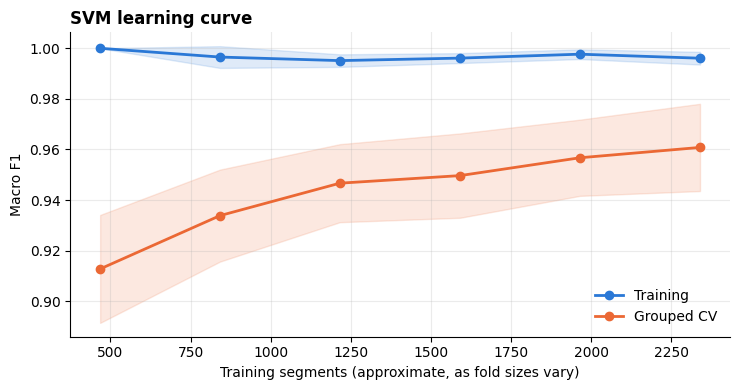

In [71]:
tuned = make_svm(C=CHOSEN_C, gamma=CHOSEN_GAMMA, class_weight=CHOSEN_WEIGHT)
sizes, train_scores, val_scores = learning_curve(
    tuned, X_train_raw, y_train, groups=groups_train, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 6), shuffle=True, random_state=RANDOM_SEED, n_jobs=-1)

curve = pd.DataFrame({"train_segments": sizes,
                      "train_macro_f1": train_scores.mean(axis=1),
                      "cv_macro_f1": val_scores.mean(axis=1)})
curve["gap"] = curve["train_macro_f1"] - curve["cv_macro_f1"]
print(curve.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4))
for scores, color, label in [(train_scores, "#2a78d6", "Training"), (val_scores, "#eb6834", "Grouped CV")]:
    mean, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, mean, marker="o", linewidth=2, color=color, label=label)
    ax.fill_between(sizes, mean - std, mean + std, color=color, alpha=0.15)
ax.set_title("SVM learning curve", loc="left", fontweight="bold")
ax.set_xlabel("Training segments (approximate, as fold sizes vary)")
ax.set_ylabel("Macro F1")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("plots/svm_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

In [72]:
# Final SVM on the scaled training data. probability=True gives the predict_proba the final notebooks need.
best_params = {"C": CHOSEN_C, "gamma": CHOSEN_GAMMA, "class_weight": CHOSEN_WEIGHT, "kernel": "rbf"}
best_model = SVC(**best_params, probability=True, random_state=RANDOM_SEED)
best_model.fit(X_train, y_train)

tuned_cv = grouped_cv(tuned, "Tuned RBF SVM")
val_results = evaluate(best_model, X_val, y_val)

print("Chosen settings:", best_params)
print(f"Support vectors: {best_model.n_support_.sum()} of {len(X_train)} "
      f"(per class {dict(zip(classes, best_model.n_support_))})")
print(f"Grouped CV macro F1: {tuned_cv['cv_macro_f1']:.3f} (train {tuned_cv['train_macro_f1']:.3f}, gap {tuned_cv['gap']:.3f})")
print(f"Validation macro F1: {val_results['macro_f1']:.3f} (Dummy was 0.320)")
print()
print(pd.Series(val_results).round(3).to_string())
print()
print(classification_report(y_val, best_model.predict(X_val), target_names=classes, digits=3))

Chosen settings: {'C': 10.0, 'gamma': 0.015151515151515152, 'class_weight': None, 'kernel': 'rbf'}
Support vectors: 214 of 2756 (per class {'ambient': np.int32(41), 'unknown': np.int32(42), 'vessel_like': np.int32(131)})
Grouped CV macro F1: 0.961 (train 0.996, gap 0.035)
Validation macro F1: 0.920 (Dummy was 0.320)

accuracy              0.982
macro_f1              0.920
roc_auc               0.998
log_loss              0.032
brier                 0.018
recall_ambient        0.895
recall_unknown        0.875
recall_vessel_like    0.990

              precision    recall  f1-score   support

     ambient      0.895     0.895     0.895        19
     unknown      0.875     0.875     0.875         8
 vessel_like      0.990     0.990     0.990       314

    accuracy                          0.982       341
   macro avg      0.920     0.920     0.920       341
weighted avg      0.982     0.982     0.982       341



## 4.1 Probability Quality
The decision support system reads `predict_proba` and flags anything under 60% confidence for review, so the probabilities matter as well as the labels.

- **Reliability:** when the model says 90%, is it right about 90% of the time?
- **Two data sources:** validation is the independent check, and out-of-fold training predictions add many more minority examples.
- **Review rule:** how much gets flagged, and does the flag catch the errors?

The SVM's probabilities come from Platt scaling inside `SVC`. Its internal folds aren't grouped by clip, which is why the out-of-fold check here is grouped.

In [73]:
LOW_CONFIDENCE_THRESHOLD = 0.60   # same value as src/utils/config.py
CONF_BINS = [0, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]


def confidence_table(y, prob):
    """Compare stated confidence with actual accuracy, in confidence bands."""
    conf = np.clip(prob.max(axis=1), 0, 1)
    correct = prob.argmax(axis=1) == y
    bands = pd.cut(conf, CONF_BINS, include_lowest=True)
    table = (pd.DataFrame({"conf": conf, "correct": correct})
             .groupby(bands, observed=True)
             .agg(segments=("conf", "size"), mean_confidence=("conf", "mean"), accuracy=("correct", "mean")))
    table["gap"] = table["mean_confidence"] - table["accuracy"]
    return table


def probability_summary(y, prob, label):
    """ECE is the average gap between confidence and accuracy, weighted by band size."""
    table = confidence_table(y, prob)
    onehot = np.eye(num_classes)[y]
    pred = prob.argmax(axis=1)
    return {"data": label,
            "segments": len(y),
            "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
            "accuracy": (pred == y).mean(),
            "mean_confidence": prob.max(axis=1).mean(),
            "ece": (table["segments"] / len(y) * table["gap"].abs()).sum(),
            "log_loss": log_loss(y, prob, labels=list(range(num_classes))),
            "brier": np.mean(np.sum((prob - onehot) ** 2, axis=1))}


def plot_reliability(series, title, filename):
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0.3, 1], [0.3, 1], color="#52514e", linestyle="--", linewidth=1.5, label="Perfect calibration")
    for (label, (y, prob)), color in zip(series.items(), ["#2a78d6", "#eb6834"]):
        table = confidence_table(y, prob)
        ax.plot(table["mean_confidence"], table["accuracy"], marker="o", markersize=7,
                linewidth=2, color=color, label=label)
    ax.set_xlim(0.3, 1.02)
    ax.set_ylim(0.0, 1.02)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("Stated confidence")
    ax.set_ylabel("Actual accuracy")
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

               data  segments  macro_f1  accuracy  mean_confidence   ece  log_loss  brier
Train (out-of-fold)      2756     0.958     0.992            0.988 0.005     0.042  0.014
         Validation       341     0.951     0.988            0.986 0.009     0.032  0.018

Out-of-fold confidence bands:
               segments  mean_confidence  accuracy    gap
(-0.001, 0.6]        12            0.553     0.333  0.220
(0.6, 0.7]           15            0.660     0.867 -0.207
(0.7, 0.8]           19            0.749     0.947 -0.198
(0.8, 0.9]           28            0.856     0.893 -0.036
(0.9, 0.95]          46            0.925     1.000 -0.075
(0.95, 1.0]        2636            0.996     0.997 -0.000

Validation confidence bands:
               segments  mean_confidence  accuracy    gap
(-0.001, 0.6]         3            0.559     0.667 -0.107
(0.6, 0.7]            1            0.605     0.000  0.605
(0.7, 0.8]            2            0.706     1.000 -0.294
(0.8, 0.9]            4        

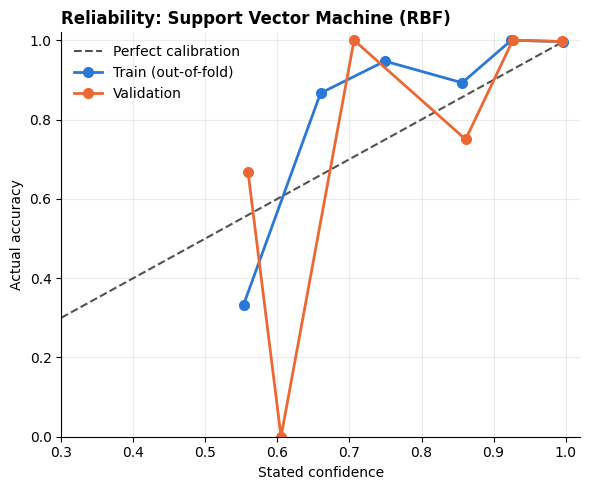

In [74]:
OOF_MODEL = make_svm(C=CHOSEN_C, gamma=CHOSEN_GAMMA, class_weight=CHOSEN_WEIGHT, probability=True)

# Out-of-fold probabilities: each training segment is scored by a model that never saw its clip.
# This gives far more minority examples than the validation set (153 ambient and 66 unknown).
oof_prob = cross_val_predict(OOF_MODEL, X_train_raw, y_train, groups=groups_train, cv=cv,
                             method="predict_proba", n_jobs=-1)
val_prob = best_model.predict_proba(X_val)

print(pd.DataFrame([probability_summary(y_train, oof_prob, "Train (out-of-fold)"),
                    probability_summary(y_val, val_prob, "Validation")]).round(3).to_string(index=False))
print("\nOut-of-fold confidence bands:")
print(confidence_table(y_train, oof_prob).round(3))
print("\nValidation confidence bands:")
print(confidence_table(y_val, val_prob).round(3))

disagree = (best_model.predict(X_val) != val_prob.argmax(axis=1)).sum()
print(f"\nValidation segments where predict() and the top probability disagree: {disagree} of {len(y_val)}")

plot_reliability({"Train (out-of-fold)": (y_train, oof_prob), "Validation": (y_val, val_prob)},
                 f"Reliability: {ALGO_NAME}", f"plots/calibration_{FILE_SLUG}.png")

In [75]:
# How well does the decision system's review rule work with this model?
final_prob = best_model.predict_proba(X_val)
final_conf = final_prob.max(axis=1)
final_correct = final_prob.argmax(axis=1) == y_val
flagged = final_conf < LOW_CONFIDENCE_THRESHOLD
errors = ~final_correct

print(f"Flagged for review (confidence < {LOW_CONFIDENCE_THRESHOLD:.0%}): {flagged.sum()} of {len(y_val)} ({flagged.mean():.1%})")
print(f"Accuracy of segments kept: {final_correct[~flagged].mean():.3f} ({(~flagged).sum()} segments)")
if flagged.any():
    print(f"Accuracy of segments flagged: {final_correct[flagged].mean():.3f} ({flagged.sum()} segments)")
print(f"Errors caught by the flag: {(flagged & errors).sum()} of {errors.sum()}")
print(f"Errors made with high confidence (at least 90%): {(errors & (final_conf >= 0.9)).sum()} of {errors.sum()}")
print("\nShare of each true class flagged:")
for i, cls in enumerate(classes):
    print(f"  {cls:<12} {flagged[y_val == i].mean():.1%} of {(y_val == i).sum()} segments")

Flagged for review (confidence < 60%): 3 of 341 (0.9%)
Accuracy of segments kept: 0.991 (338 segments)
Accuracy of segments flagged: 0.667 (3 segments)
Errors caught by the flag: 1 of 4
Errors made with high confidence (at least 90%): 1 of 4

Share of each true class flagged:
  ambient      0.0% of 19 segments
  unknown      12.5% of 8 segments
  vessel_like  0.6% of 314 segments


## 5. Final Evaluation on the Held-Out Test Set
This is the first time the tuned model sees the test set, and these are the scores to report. **Don't change any settings because of them.** The next cell stops the run if the settings differ from the ones frozen after Phase 5.

Each confidence interval resamples whole **clips**, because segments from one clip aren't independent. It shows how much the score could move with a different sample, which matters because the test set has only 20 `ambient` and 9 `unknown` segments.

In [76]:
# Stop here if the settings differ from those frozen after Phase 5
assert CHOSEN_C == 10.0 and abs(CHOSEN_GAMMA - 1 / 66) < 1e-9 and CHOSEN_WEIGHT is None, \
    f"Settings changed from the frozen choice: {best_params}"
print("Frozen settings confirmed:", best_params)

Frozen settings confirmed: {'C': 10.0, 'gamma': 0.015151515151515152, 'class_weight': None, 'kernel': 'rbf'}


In [77]:
# Timing only: fit a copy, so the frozen model itself isn't changed
t0 = time.time()
clone(best_model).fit(X_train, y_train)
train_time = time.time() - t0

# Latency for one segment
t_start = time.perf_counter()
for _ in range(100):
    best_model.predict(X_test[:1])
latency_ms = (time.perf_counter() - t_start) / 100 * 1000

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)

test_metrics = {
    "test_accuracy": accuracy_score(y_test, y_pred),
    "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "roc_auc_macro": roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"),
    "latency_ms": latency_ms,
    "training_time_s": train_time,
}
print(f"=== {ALGO_NAME}: FINAL TEST RESULTS ===")
for name, value in test_metrics.items():
    print(f"{name:<18} {value:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=classes, digits=3, zero_division=0))
print(pd.Series(probability_summary(y_test, y_prob, "Test")).to_string())

=== Support Vector Machine (RBF): FINAL TEST RESULTS ===
test_accuracy      0.9813
macro_precision    0.9169
macro_recall       0.8571
macro_f1           0.8852
roc_auc_macro      0.9787
latency_ms         0.1102
training_time_s    0.1702

              precision    recall  f1-score   support

     ambient      0.889     0.800     0.842        20
     unknown      0.875     0.778     0.824         9
 vessel_like      0.987     0.993     0.990       453

    accuracy                          0.981       482
   macro avg      0.917     0.857     0.885       482
weighted avg      0.981     0.981     0.981       482

data                   Test
segments                482
macro_f1           0.901578
accuracy           0.985477
mean_confidence    0.990928
ece                0.010564
log_loss           0.062908
brier                0.0223


In [78]:
# predict() is the main score. The decision system uses the top probability instead.
top_pred = y_prob.argmax(axis=1)
print(f"Segments where predict() and the top probability disagree: {(y_pred != top_pred).sum()} of {len(y_test)}")
print(f"Macro F1 with predict():         {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Macro F1 with top probability:   {f1_score(y_test, top_pred, average='macro'):.4f}")
print(f"Accuracy with predict():         {accuracy_score(y_test, y_pred):.4f}")
print(f"Accuracy with top probability:   {accuracy_score(y_test, top_pred):.4f}")

Segments where predict() and the top probability disagree: 2 of 482
Macro F1 with predict():         0.8852
Macro F1 with top probability:   0.9016
Accuracy with predict():         0.9813
Accuracy with top probability:   0.9855


In [79]:
def bootstrap_clip_ci(y, pred, clips, n_boot=2000):
    """95% interval for macro F1 and accuracy, resampling whole clips."""
    rng = np.random.default_rng(RANDOM_SEED)
    positions = list(pd.DataFrame({"clip": clips}).groupby("clip").indices.values())
    labels = list(range(num_classes))
    f1s, accs = [], []
    for _ in range(n_boot):
        picks = rng.integers(0, len(positions), len(positions))
        idx = np.concatenate([positions[p] for p in picks])
        f1s.append(f1_score(y[idx], pred[idx], average="macro", labels=labels, zero_division=0))
        accs.append((y[idx] == pred[idx]).mean())
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(accs, [2.5, 97.5])


test_clips = df.loc[test_mask, "source_clip_id"].values
f1_ci, acc_ci = bootstrap_clip_ci(y_test, y_pred, test_clips)
print(f"Test clips: {len(set(test_clips))} clips, {len(y_test)} segments")
print(f"Macro F1: {test_metrics['macro_f1']:.3f} (95% interval {f1_ci[0]:.3f} to {f1_ci[1]:.3f})")
print(f"Accuracy: {test_metrics['test_accuracy']:.3f} (95% interval {acc_ci[0]:.3f} to {acc_ci[1]:.3f})")

Test clips: 91 clips, 482 segments
Macro F1: 0.885 (95% interval 0.780 to 0.955)
Accuracy: 0.981 (95% interval 0.947 to 0.993)


## 6. Confusion Matrix, ROC Curves and Precision-Recall Curves
Precision-recall curves are included because they show the rare classes more honestly than ROC curves when one class dominates.

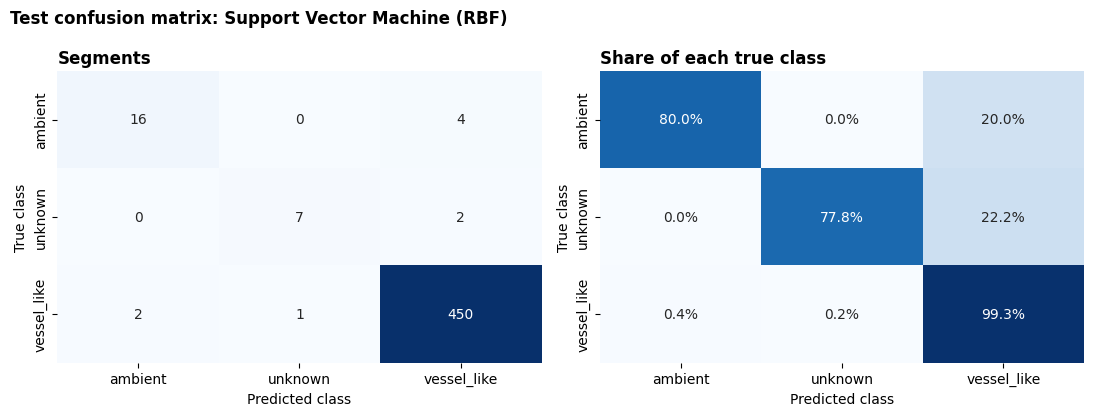

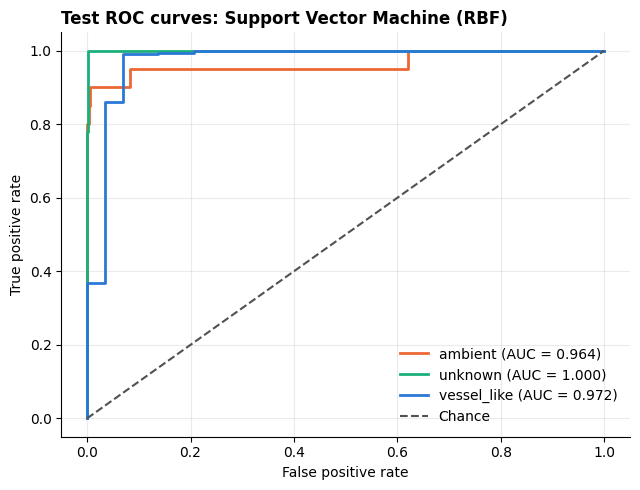

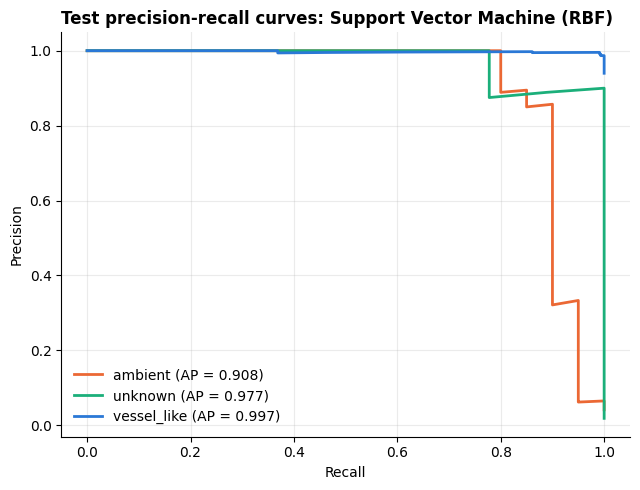

In [80]:
CLASS_COLORS = {"vessel_like": "#2a78d6", "ambient": "#eb6834", "unknown": "#1baf7a"}

cm = confusion_matrix(y_test, y_pred, labels=range(num_classes))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title("Segments", loc="left", fontweight="bold")
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title("Share of each true class", loc="left", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
fig.suptitle(f"Test confusion matrix: {ALGO_NAME}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(f"plots/confusion_matrix_{FILE_SLUG}.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test == i, y_prob[:, i])
    ax.plot(fpr, tpr, linewidth=2, color=CLASS_COLORS[cls], label=f"{cls} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], color="#52514e", linestyle="--", linewidth=1.5, label="Chance")
ax.set_title(f"Test ROC curves: {ALGO_NAME}", loc="left", fontweight="bold")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(f"plots/roc_curves_{FILE_SLUG}.png", dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
for i, cls in enumerate(classes):
    precision, recall, _ = precision_recall_curve(y_test == i, y_prob[:, i])
    ap = average_precision_score(y_test == i, y_prob[:, i])
    ax.plot(recall, precision, linewidth=2, color=CLASS_COLORS[cls], label=f"{cls} (AP = {ap:.3f})")
ax.set_title(f"Test precision-recall curves: {ALGO_NAME}", loc="left", fontweight="bold")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig(f"plots/pr_curves_{FILE_SLUG}.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Error Analysis and Feature Importance
The source breakdown tests the main risk from `eda_person2.ipynb`: whether the model performs differently on real and synthetic audio. Permutation importance uses the **validation** set, so the test set only measures performance.

In [81]:
meta = pd.read_csv("../data/metadata/master_metadata.csv")
clip_source = dict(zip(meta["clip_id"], meta["source_dataset"]))

results = pd.DataFrame({
    "clip": test_clips,
    "source": [clip_source[c] for c in test_clips],
    "true": [classes[i] for i in y_test],
    "pred": [classes[i] for i in y_pred],
    "confidence": y_prob.max(axis=1),
    "poor_quality": df.loc[test_mask, "is_poor_quality"].values,
})
results["correct"] = results["true"] == results["pred"]

print("Recall by true class and data source:")
print(results.groupby(["true", "source"]).agg(segments=("correct", "size"), recall=("correct", "mean")).round(3))
print("\nAccuracy by data source:")
print(results.groupby("source").agg(segments=("correct", "size"), accuracy=("correct", "mean")).round(3))
print("\nAccuracy by recording quality (1 = poor):")
print(results.groupby("poor_quality").agg(segments=("correct", "size"), accuracy=("correct", "mean")).round(3))

errors = results[~results["correct"]]
print(f"\nErrors: {len(errors)} of {len(results)}, from {errors['clip'].nunique()} clips")
print("\nTrue class (rows) against predicted class (columns), errors only:")
print(pd.crosstab(errors["true"], errors["pred"]))
print("\nClips with the most errors:")
print(errors["clip"].value_counts().head(5).to_string())
print("\nMost confident errors:")
print(errors.sort_values("confidence", ascending=False)
      .head(10)[["source", "true", "pred", "confidence", "poor_quality"]].round(3).to_string(index=False))

Recall by true class and data source:
                       segments  recall
true        source                     
ambient     ShipsEar          4   0.250
            Synthetic        16   0.938
unknown     Synthetic         9   0.778
vessel_like DeepShip        398   0.995
            ShipsEar         38   1.000
            Synthetic        17   0.941

Accuracy by data source:
           segments  accuracy
source                       
DeepShip        398     0.995
ShipsEar         42     0.929
Synthetic        42     0.905

Accuracy by recording quality (1 = poor):
              segments  accuracy
poor_quality                    
0.0                434     0.979
1.0                 48     1.000

Errors: 9 of 482, from 9 clips

True class (rows) against predicted class (columns), errors only:
pred         ambient  unknown  vessel_like
true                                      
ambient            0        0            4
unknown            0        0            2
vessel_like        2

                     feature  mean_f1_drop    std
           delta_mfcc_2_mean        0.0066 0.0152
      spectral_bandwidth_max        0.0061 0.0084
 spectral_contrast_band5_max        0.0029 0.0182
spectral_contrast_band5_mean        0.0000 0.0000
       spectral_flatness_min        0.0000 0.0000
    spectral_flatness_median       -0.0009 0.0026
                  zcr_median       -0.0012 0.0144
    spectral_centroid_median       -0.0020 0.0060
                 mfcc_10_std       -0.0021 0.0078
            delta_mfcc_1_std       -0.0024 0.0061
            delta_mfcc_1_max       -0.0025 0.0109
 spectral_contrast_band2_min       -0.0036 0.0054
            delta_mfcc_1_min       -0.0040 0.0080
                 mfcc_1_mean       -0.0040 0.0061
spectral_contrast_band2_mean       -0.0047 0.0043


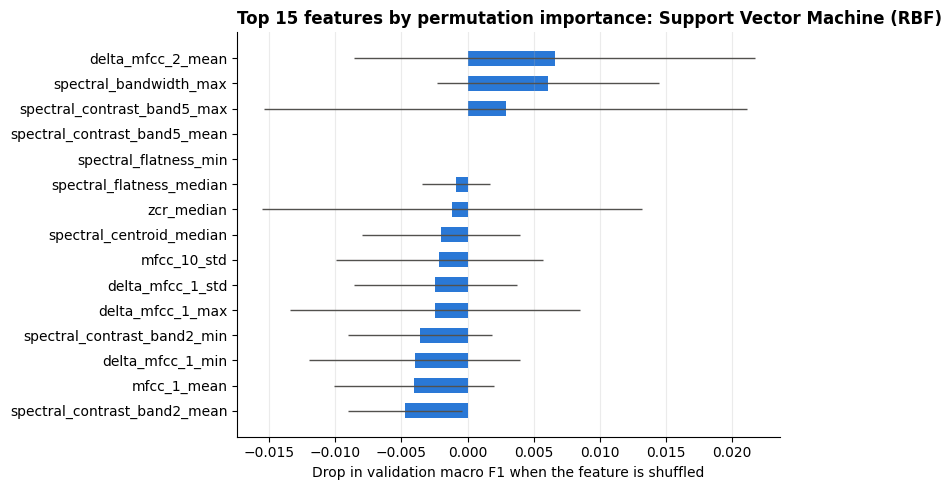

In [82]:
perm = permutation_importance(best_model, X_val, y_val, scoring="f1_macro",
                              n_repeats=20, random_state=RANDOM_SEED, n_jobs=-1)
importance = pd.DataFrame({"feature": feature_cols,
                           "mean_f1_drop": perm.importances_mean,
                           "std": perm.importances_std}).sort_values("mean_f1_drop", ascending=False)
print(importance.head(15).round(4).to_string(index=False))

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["feature"], top["mean_f1_drop"], xerr=top["std"], color="#2a78d6", height=0.6,
        error_kw={"ecolor": "#52514e", "linewidth": 1})
ax.set_title(f"Top 15 features by permutation importance: {ALGO_NAME}", loc="left", fontweight="bold")
ax.set_xlabel("Drop in validation macro F1 when the feature is shuffled")
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(f"plots/permutation_importance_{FILE_SLUG}.png", dpi=200, bbox_inches="tight")
plt.show()

In [83]:
cv_score = tuned_cv["cv_macro_f1"]
cv_label = "Grouped CV"

print(f"{ALGO_NAME}: macro F1 at each stage")
print(f"  {cv_label:<20} {cv_score:.3f}")
print(f"  {'Validation':<20} {f1_score(y_val, best_model.predict(X_val), average='macro'):.3f}")
print(f"  {'Test':<20} {test_metrics['macro_f1']:.3f} (95% interval {f1_ci[0]:.3f} to {f1_ci[1]:.3f})")

Support Vector Machine (RBF): macro F1 at each stage
  Grouped CV           0.961
  Validation           0.920
  Test                 0.885 (95% interval 0.780 to 0.955)


## 8. Export Model Artifacts
Saves the final model, scaler, label encoder and metrics for the final comparison.

Before saving, the score is checked against the result recorded in Phase 6. After saving, the files are loaded again and tested the same way the final comparison notebook uses them, on the raw test features.

In [84]:
RECORDED_TEST_F1 = 0.8852   # final result recorded in Phase 6
extra_metrics = {
    "macro_f1_top_probability": float(f1_score(y_test, y_prob.argmax(axis=1), average="macro")),
    "accuracy_top_probability": float(accuracy_score(y_test, y_prob.argmax(axis=1))),
}
assert abs(test_metrics["macro_f1"] - RECORDED_TEST_F1) < 0.001, \
    f"Test macro F1 {test_metrics['macro_f1']:.4f} differs from the recorded result. Nothing was saved."

joblib.dump(best_model, f"models/model_{FILE_SLUG}.joblib")
joblib.dump(scaler,     f"models/scaler_{FILE_SLUG}.joblib")
joblib.dump(le,         f"models/label_encoder_{FILE_SLUG}.joblib")

metrics = {
    "algorithm": ALGO_NAME,
    "slug": FILE_SLUG,
    "best_hyperparameters": best_params,
    **{name: float(value) for name, value in test_metrics.items()},
    "macro_f1_ci_95": [float(f1_ci[0]), float(f1_ci[1])],
    **extra_metrics,
    "classes": classes,
    "feature_count": len(feature_cols),
}
with open(f"models/metrics_{FILE_SLUG}.json", "w") as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))

{
  "algorithm": "Support Vector Machine (RBF)",
  "slug": "svm_rbf",
  "best_hyperparameters": {
    "C": 10.0,
    "gamma": 0.015151515151515152,
    "class_weight": null,
    "kernel": "rbf"
  },
  "test_accuracy": 0.9813278008298755,
  "macro_precision": 0.9169103313840156,
  "macro_recall": 0.8570517537404955,
  "macro_f1": 0.8852445616078635,
  "roc_auc_macro": 0.9787280068126285,
  "latency_ms": 0.11023400002159178,
  "training_time_s": 0.1701517105102539,
  "macro_f1_ci_95": [
    0.7798732425622011,
    0.9545177318158211
  ],
  "macro_f1_top_probability": 0.9015781455892516,
  "accuracy_top_probability": 0.9854771784232366,
  "classes": [
    "ambient",
    "unknown",
    "vessel_like"
  ],
  "feature_count": 66
}


In [85]:
# Load the saved files fresh and use them the way the final comparison notebook does
saved_model = joblib.load(f"models/model_{FILE_SLUG}.joblib")
saved_scaler = joblib.load(f"models/scaler_{FILE_SLUG}.joblib")
saved_encoder = joblib.load(f"models/label_encoder_{FILE_SLUG}.joblib")

fresh = pd.read_csv("../data/features/features.csv")
fresh_test = fresh[fresh["split"] == "test"]
raw_features = np.nan_to_num(fresh_test[feature_cols].values, nan=0.0)
fresh_classes = sorted(fresh["label"].unique())
fresh_y = fresh_test["label"].map({c: i for i, c in enumerate(fresh_classes)}).values

ready = saved_scaler.transform(raw_features) if saved_scaler else raw_features
saved_pred = saved_model.predict(ready)
saved_prob = saved_model.predict_proba(ready)

assert raw_features.shape[1] == 66 and ready.shape[1] == 66
assert list(saved_encoder.classes_) == fresh_classes
assert (saved_pred == y_pred).all(), "Saved model predictions differ from the notebook."
assert np.allclose(saved_prob, y_prob), "Saved model probabilities differ from the notebook."
saved_f1 = f1_score(fresh_y, saved_pred, average="macro")
assert abs(saved_f1 - test_metrics["macro_f1"]) < 1e-9
print(f"Saved files reproduce the results: macro F1 = {saved_f1:.4f}, with {ready.shape[1]} features")

# Leftovers from the old skeleton. The final notebook only uses these if the named files are missing.
for leftover in ["models/model.joblib", "models/scaler.joblib"]:
    Path(leftover).unlink(missing_ok=True)
print("Files in models/:", sorted(p.name for p in Path("models").iterdir() if p.name != ".gitkeep"))

Saved files reproduce the results: macro F1 = 0.8852, with 66 features
Files in models/: ['label_encoder_naive_bayes.joblib', 'label_encoder_svm_rbf.joblib', 'metrics_naive_bayes.json', 'metrics_svm_rbf.json', 'model_naive_bayes.joblib', 'model_svm_rbf.joblib', 'nb_tuning_results.csv', 'scaler_naive_bayes.joblib', 'scaler_svm_rbf.joblib', 'svm_tuning_results.csv']


## 9. Conclusions

**Final settings:** `StandardScaler`, `C=10`, `gamma=0.01515`, `class_weight=None`, `probability=True`

| Macro F1 by stage | Score |
|---|---:|
| Dummy baseline (validation) | 0.320 |
| Grouped CV | 0.961 |
| Validation | 0.920 |
| **Test** | **0.885** (95% interval 0.780 to 0.955) |

| Test results | Value |
|---|---:|
| Accuracy | 98.1% |
| ROC-AUC | 0.979 |
| Log loss | 0.063 |
| Expected calibration error | 0.011 |
| Latency per segment | About 0.11 ms |
| Recall: `ambient` / `unknown` / `vessel_like` | 0.800 / 0.778 / 0.993 |

**What was learned**
- **The RBF kernel adds value:** tuned, it beats a default linear kernel by 0.073 in grouped CV, so the class boundaries aren't linear.
- **Tuning helped:** grouped CV macro F1 rose from 0.915 to 0.961.
- **Overfitting is mild:** the train and CV gap is 0.035, and the learning curve suggests more data would still help.
- **The probabilities are trustworthy overall:** confidence closely matches accuracy, although some errors are made with high confidence.
- **`predict()` and top probability differ slightly:** macro F1 is 0.885 with `predict()` and 0.902 with top probability, from 2 of 482 segments.

**Limitations**
- **Real ambient audio:** only 1 of 4 real ShipsEar `ambient` test segments was recognized, against 15 of 16 synthetic ones. The sample is small, so this is a warning and not a measurement, but it matches the source differences in `eda_person2.ipynb`.
- **Synthetic-heavy classes:** all `unknown` clips and most `ambient` clips are synthetic, so results may not carry over to real recordings.
- **Few minority segments:** the test set has 20 `ambient` and 9 `unknown` segments, which is why the interval is wide.
- **`marine_life` has no data:** the model covers 3 of the 4 planned classes.
- **The 60% review rule:** it catches only some errors, so it shouldn't be the only safeguard.
- **Choices made along the way:** `class_weight` was chosen after `C` and `gamma`, and those weren't re-tuned afterwards.